<a href="https://colab.research.google.com/github/geovisiontech/DACS/blob/dev-logs/techsolutionslog1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime


In [7]:
from google.colab import drive

# Mount Google drive to the colab environment
drive.mount('/content/drive')

# Define the correct file path based on our search
security_logs_path = '/content/drive/MyDrive/techsolutions_logs 1.csv'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
# Load the dataset into a Pandas DataFrame using the corrected path
df = pd.read_csv(security_logs_path)
df.head(15)

,timestamp,user,ip_address,action,success,file
0,2026-09-01 07:16:13,aotieno,198.51.100.21,logout,yes,NaN
1,2026-09-01 08:02:20,jkamau,192.0.2.12,login_success,yes,NaN
2,2026-09-01 08:47:13,ceo_assistant,192.0.2.10,login_success,yes,NaN
3,2026-09-01 10:54:26,hr01,192.0.2.10,login_failure,no,NaN
4,2026-09-01 11:07:59,admin,203.0.113.16,data_export,yes,financial_report.pdf
5,2026-09-01 13:05:13,njeri,198.51.100.21,file_access,yes,financial_report.pdf
6,2026-09-01 13:38:59,kmutua,192.0.2.10,login_success,yes,NaN
7,2026-09-01 13:39:56,it_support,192.0.2.12,logout,yes,NaN
8,2026-09-01 15:26:03,finance01,198.51.100.21,login_success,yes,NaN
9,2026-09-01 15:33:46,kmutua,198.51.100.21,logout,yes,NaN


In [9]:
df.info()
df.describe()
# df.head(10)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   timestamp   505 non-null    object
 1   user        505 non-null    object
 2   ip_address  505 non-null    object
 3   action      505 non-null    object
 4   success     505 non-null    object
 5   file        142 non-null    object
dtypes: object(6)
memory usage: 23.8+ KB


,timestamp,user,ip_address,action,success,file
count,505,505,505,505,505,142
unique,505,10,9,7,2,6
top,2026-09-01 07:16:13,admin,198.51.100.20,login_success,yes,incident_response_plan.docx
freq,1,71,68,167,384,26


In [10]:
missing_values = df.isnull().sum()
print("Missing values per column:\n", missing_values)


Missing values per column:
 timestamp       0
user            0
ip_address      0
action          0
success         0
file          363
dtype: int64


In [11]:
df['success'].value_counts()


,count
success,
yes,384
no,121


In [12]:
# Count failed login attempts per IP
# Filter the DataFrame to include only where the success status is no
failed_events = df[df['success'] == 'no']
# failed_events.head(30)

# Group failed events by 'ip_address'
failed_events_per_ip = failed_events.groupby('ip_address')['success'].count().sort_values(ascending=False)

# Display the top 10 IP addresses with the most failed login attempts
failed_events_per_ip.head(10)


,success
ip_address,
203.0.113.250,48
198.51.100.250,19
198.51.100.20,12
203.0.113.16,10
192.0.2.10,8
192.0.2.11,7
198.51.100.21,6
203.0.113.15,6
192.0.2.12,5


In [13]:
# The top IP is the strongest indicator of a threat
top_ips = failed_events_per_ip.index[:2]
print("The top IPs are:", top_ips)

The top IPs are: Index(['203.0.113.250', '198.51.100.250'], dtype='object', name='ip_address')


In [14]:
# Count failed login attempts per user
# Group by 'user' and count how many times each account was targeted
targeted_user = failed_events.groupby('user')['success'].count().sort_values(ascending=False)

# Display the top 10 users with the most failed login attempts
targeted_user.head(10)

,success
user,
admin,25
jkamau,22
ceo_assistant,21
finance01,16
it_support,11
aotieno,7
hr01,6
mwangi,6
njeri,4


In [15]:
top_targeted_user = targeted_user.index[0]
print("The top targeted user is:", top_targeted_user)

The top targeted user is: admin


In [16]:
#Filter for successful critical actions that are suspicious/critical
critical_success= df[(df['success'] == 'yes') & (df['action'].isin(['login_success', 'data_export', 'password_reset']))]
critical_success.head(10)

,timestamp,user,ip_address,action,success,file
1,2026-09-01 08:02:20,jkamau,192.0.2.12,login_success,yes,NaN
2,2026-09-01 08:47:13,ceo_assistant,192.0.2.10,login_success,yes,NaN
4,2026-09-01 11:07:59,admin,203.0.113.16,data_export,yes,financial_report.pdf
6,2026-09-01 13:38:59,kmutua,192.0.2.10,login_success,yes,NaN
8,2026-09-01 15:26:03,finance01,198.51.100.21,login_success,yes,NaN
10,2026-09-01 16:37:35,njeri,198.51.100.21,login_success,yes,NaN
11,2026-09-02 05:17:24,ceo_assistant,198.51.100.21,login_success,yes,NaN
14,2026-09-02 08:05:40,finance01,203.0.113.16,login_success,yes,NaN
15,2026-09-02 08:42:07,hr01,192.0.2.12,login_success,yes,NaN
21,2026-09-02 12:48:41,njeri,192.0.2.12,login_success,yes,NaN


In [17]:
#Display the crucial details
critical_success[['user', 'ip_address', 'timestamp', 'action']]

# Confirm the compromised users
compromised_users = critical_success['user'].unique()
print("The compromised users are:", ', '.join(compromised_users))

The compromised users are: jkamau, ceo_assistant, admin, kmutua, finance01, njeri, hr01, mwangi, it_support, aotieno


/tmp/ipykernel_2060/3019014372.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=success_count.index, y=success_count.values, palette=['lightgreen', 'salmon'])


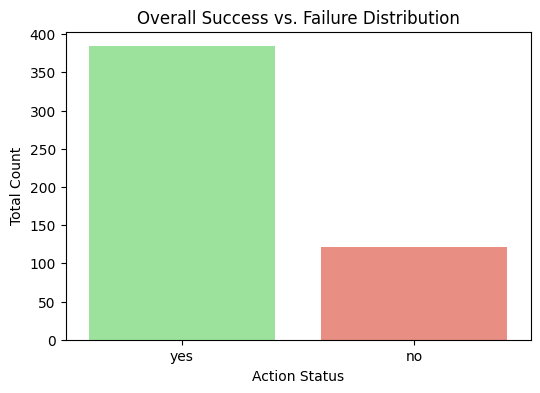

In [18]:
# Count the instances of yes and no actions
success_count = df['success'].value_counts()

plt.figure(figsize=(6, 4))
sns.barplot(x=success_count.index, y=success_count.values, palette=['lightgreen', 'salmon'])
plt.title('Overall Success vs. Failure Distribution')
plt.xlabel('Action Status')
plt.ylabel('Total Count')
plt.show()

/tmp/ipykernel_2060/937947474.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=failed_events_per_ip.index, y=failed_events_per_ip.values, palette='viridis')


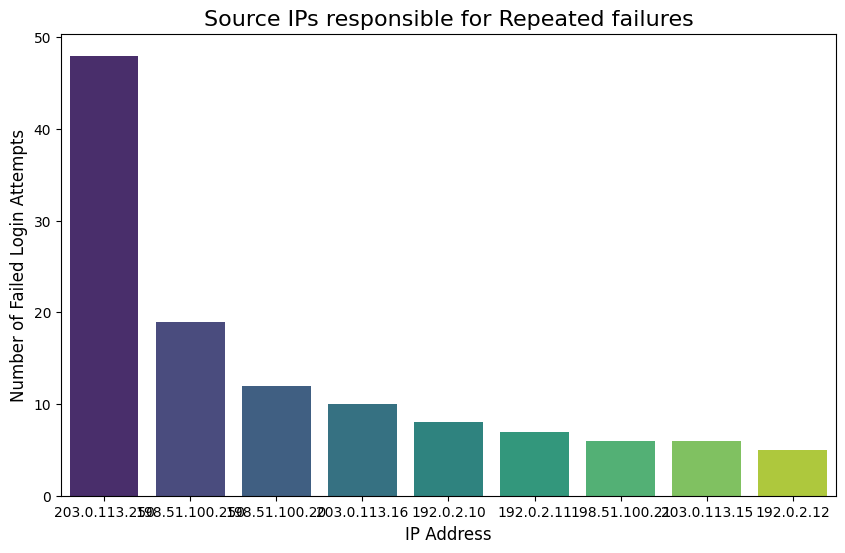

In [19]:
# Count failed login attempts per IP
plt.figure(figsize=(10, 6))
sns.barplot(x=failed_events_per_ip.index, y=failed_events_per_ip.values, palette='viridis')
plt.title('Source IPs responsible for Repeated failures', fontsize=16)
plt.xlabel('IP Address', fontsize=12)
plt.ylabel('Number of Failed Login Attempts', fontsize=12)
# plt.xticks(rotation=90, ha='right', fontsize=8)
plt.show()

In [21]:
suspicious_file_actions = df[
    (df['success'] == 'yes') &      #successful action
    (df['file'].notna()) &          # A 'file' column value is present
    (~df['action'].isin(['file_upload', 'data_export']))     # action is not a file upload/export
]
suspicious_file_actions.head()


,timestamp,user,ip_address,action,success,file
5,2026-09-01 13:05:13,njeri,198.51.100.21,file_access,yes,financial_report.pdf
12,2026-09-02 06:33:02,mwangi,203.0.113.16,file_access,yes,payroll_q3.xlsx
20,2026-09-02 12:19:50,hr01,192.0.2.10,file_access,yes,customer_database.csv
23,2026-09-02 13:15:45,hr01,198.51.100.20,file_access,yes,customer_database.csv
37,2026-09-03 13:28:00,it_support,203.0.113.16,file_access,yes,network_config_backup.zip


In [22]:
# Create the 'hour' column that is necessary for time-based analysis
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['hour'] = df['timestamp'].dt.hour
df.head()
# print(df[['timestamp', 'hour', 'action']].head(20))

,timestamp,user,ip_address,action,success,file,hour
0,2026-09-01 07:16:13,aotieno,198.51.100.21,logout,yes,NaN,7
1,2026-09-01 08:02:20,jkamau,192.0.2.12,login_success,yes,NaN,8
2,2026-09-01 08:47:13,ceo_assistant,192.0.2.10,login_success,yes,NaN,8
3,2026-09-01 10:54:26,hr01,192.0.2.10,login_failure,no,NaN,10
4,2026-09-01 11:07:59,admin,203.0.113.16,data_export,yes,financial_report.pdf,11


In [23]:
# Suspicious hours (before 8 AM or after 5PM)
# Search for successful actions outside these periods
suspicious_hours = df[(df['hour'] < 8) | (df['hour'] > 17) & (df['success'] == 'yes')]
suspicious_hours.head()

,timestamp,user,ip_address,action,success,file,hour
0,2026-09-01 07:16:13,aotieno,198.51.100.21,logout,yes,NaN,7
11,2026-09-02 05:17:24,ceo_assistant,198.51.100.21,login_success,yes,NaN,5
12,2026-09-02 06:33:02,mwangi,203.0.113.16,file_access,yes,payroll_q3.xlsx,6
13,2026-09-02 07:26:23,njeri,198.51.100.20,file_access,yes,NaN,7
24,2026-09-03 06:23:14,jkamau,192.0.2.12,logout,yes,NaN,6


In [25]:
# Filter the suspicious data to only show critical successful actions
suspicious_actions = suspicious_hours[suspicious_hours['action'].isin(['login_success', 'data_export', 'password_reset'])]
suspicious_actions.head()

,timestamp,user,ip_address,action,success,file,hour
11,2026-09-02 05:17:24,ceo_assistant,198.51.100.21,login_success,yes,NaN,5
25,2026-09-03 07:30:22,finance01,192.0.2.12,login_success,yes,NaN,7
43,2026-09-04 06:51:57,admin,203.0.113.15,login_success,yes,NaN,6
56,2026-09-04 18:53:12,kmutua,192.0.2.11,login_success,yes,NaN,18
57,2026-09-05 07:02:02,kmutua,198.51.100.20,login_success,yes,NaN,7


In [26]:
# Count total number of actions occuring in each hour of the day
action_counts = df['hour'].value_counts().sort_index()
action_counts.head(24)

,count
hour,
0,2
1,19
2,3
4,7
5,8
6,19
7,28
8,45
9,77


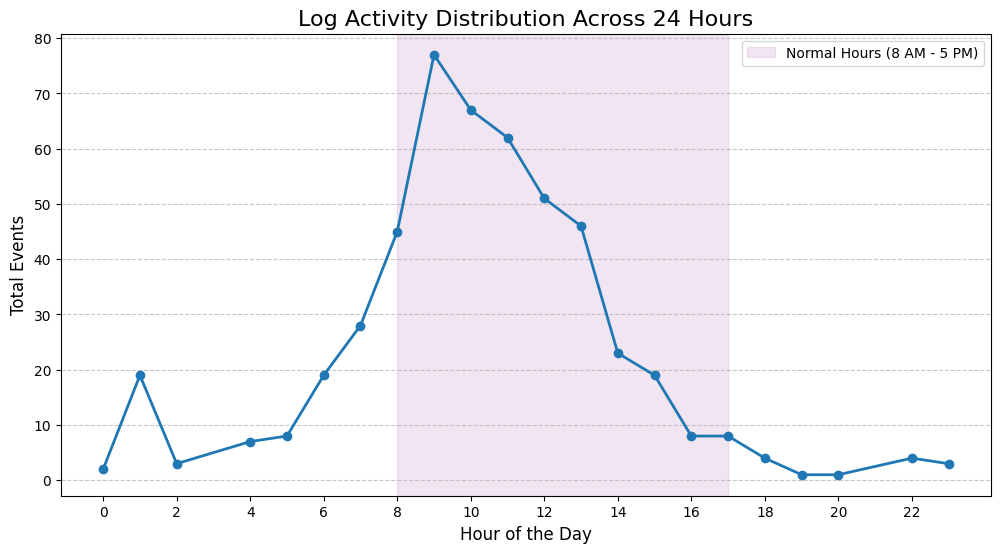

In [27]:
plt.figure(figsize=(12, 6))

# Create a line plot to show the distribution across 24 hours
plt.plot(action_counts.index, action_counts.values,
         marker='o',          # Show specific data points
         linestyle='-',       # Connect the points
         color='#1f77b4',     # Use a distinct color (e.g., standard blue)
         linewidth=2)         # Make the line slightly thicker

# Set clear title and labels
plt.title('Log Activity Distribution Across 24 Hours', fontsize=16)
plt.xlabel('Hour of the Day', fontsize=12)
plt.ylabel('Total Events', fontsize=12)

# Set the X-axis ticks to show all 24 hours (0 through 23)
plt.xticks(range(0, 24, 2))

# Add a grid for easier reading of values
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Highlight a possible "normal" working window for contrast
plt.axvspan(8, 17, color='purple', alpha=0.1, label='Normal Hours (8 AM - 5 PM)')
plt.legend()

plt.show()